## Mini Project – Python Libraries

Analyse student performance and attendance using attached excel file which has 2 tabs in the document. 
 
The goal is to:
1.	Calculate total and percentage marks.
2.	Derive attendance percentages.
3.	Classify students based on performance.
4.	Identify students with low attendance and highlight top performers.
5.	Provide visual insights into the data
  Assignment Questions
Data Preparation-
1.	Load the student marks and attendance data from the provided Excel files into two separate Pandas DataFrames.
2.	Merge the two DataFrames on the Name column to create a single DataFrame.
3.	Replace attendance values ('Y' or 'N') with numeric values (1 for 'Y' and 0 for 'N').
4.	Deal with the missing values.
5.	Do the column cleaning like name column is the combination of upper and lower case.
Data Transformation-
1.	Create separate columns for below:
o	Total marks for each student.
o	Percentage marks for each student.
o	Attendance percentage for each student based on attendance columns.
o	Calculate the weighted percentage – Attendance(40%), Mini test01(10%), Mini test02(10%), Live test(20%), Assignment (20%).
o	Use this weighted percentage for further calculations.
2.	Classify each student's performance into categories:
o	"Excellent" for percentages ≥ 85.
o	"Good" for percentages between 71 and 84.
o	"Average" for percentages between 50 and 70.
o	"Needs Improvement" for percentages < 50.
Analysis-
1.	Identify students with attendance below 75% but weighted percentage >50%.
2.	Highlight the top three students based on percentage marks.
3.	Impact of attendance on Tests/Assignment marks. 
Visualization-
1.	Create a bar chart displaying weighted percentages for top 5 students.
2.	Create a pie chart showing the distribution of students across the four performance categories.
3.	Create box plots for each test (Live Test, Mini Test 1, Mini Test 2, Assignment) to visualize the spread and detect potential    outliers in scores
4.	Create a chart to show the students where attendance is less than 50%.
5.	Any other visualization/analysis which you can infer from data for the management.



C:\Users\HP\AppData\Local\Temp\ipykernel_10292\1673102462.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[attendance_columns] = df[attendance_columns].replace({'Y':1, 'N':0}).astype(float)


,name,total_marks,percentage_marks,attendance_percentage,weighted_percentage,performance_category
0,Arjun,44.0,11.00,40.0,23.4,Needs Improvement
1,Sophia Hardy,149.0,37.25,60.0,52.1,Average
2,Raj,55.0,13.75,100.0,49.0,Needs Improvement
3,Emily,43.0,10.75,80.0,39.0,Needs Improvement
4,Ishaan Saini,40.0,10.00,20.0,14.5,Needs Improvement
...,...,...,...,...,...,...
105,Makayla,25.0,6.25,100.0,44.1,Needs Improvement
106,Ishaan Kapoor,48.0,12.00,60.0,32.1,Needs Improvement
107,Addison,40.0,10.00,100.0,46.4,Needs Improvement
108,Aditya Srivastava,35.0,8.75,40.0,22.0,Needs Improvement


,name,mini_test_1,mini_test_2,live_test,assignment,attendance_day_1,attendance_day_2,attendance_day_3,attendance_day_4,attendance_day_5,total_marks,percentage_marks,attendance_percentage,weighted_percentage,performance_category
1,Sophia Hardy,8.0,9.0,113.0,19.0,1.0,0.0,0.0,1.0,1.0,149.0,37.25,60.0,52.1,Average
2,Raj,10.0,10.0,15.0,20.0,1.0,1.0,1.0,1.0,1.0,55.0,13.75,100.0,49.0,Needs Improvement
6,Maya,10.0,10.0,15.0,20.0,0.0,0.0,0.0,1.0,1.0,55.0,13.75,40.0,25.0,Needs Improvement


,name,mini_test_1,mini_test_2,live_test,assignment,attendance_day_1,attendance_day_2,attendance_day_3,attendance_day_4,attendance_day_5,total_marks,percentage_marks,attendance_percentage,weighted_percentage,performance_category
1,Sophia Hardy,8.0,9.0,113.0,19.0,1.0,0.0,0.0,1.0,1.0,149.0,37.25,60.0,52.1,Average


,attendance_percentage,percentage_marks
attendance_percentage,1.000000,-0.001152
percentage_marks,-0.001152,1.000000


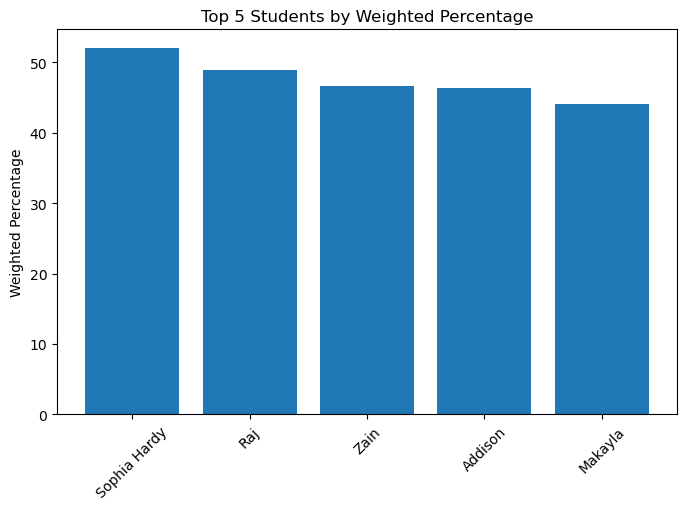

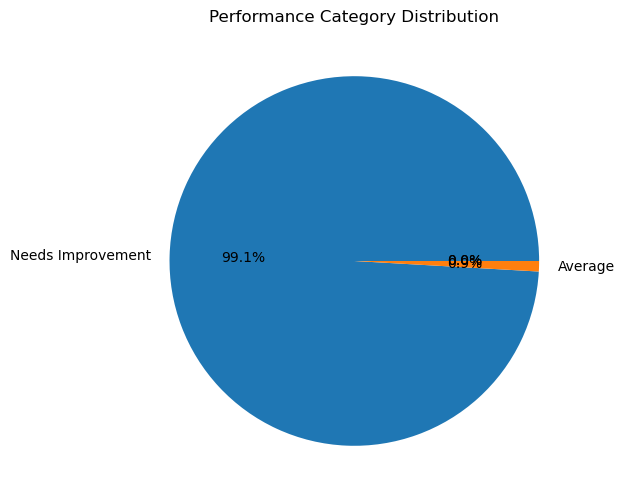

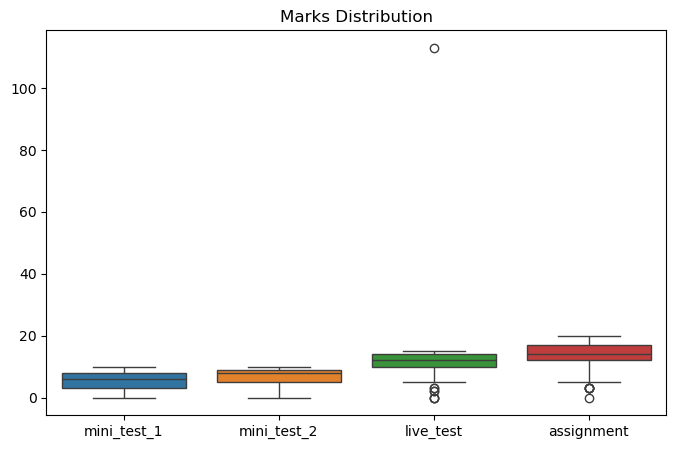

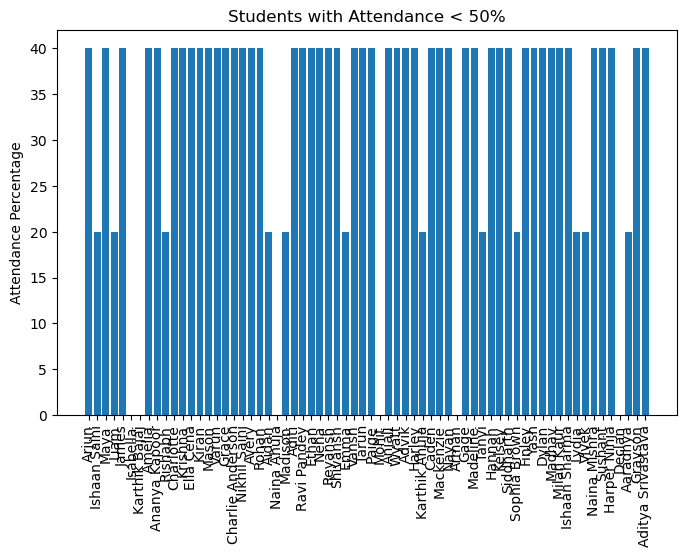

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# ======================
# LOAD DATA
# ======================
file_path = "Student Performance Analysis.xlsx"   # change only filename if needed

marks_df = pd.read_excel(file_path, sheet_name=0)
attendance_df = pd.read_excel(file_path, sheet_name=1)

# ======================
# CLEAN COLUMNS
# ======================
marks_df.columns = marks_df.columns.str.strip().str.lower().str.replace(" ", "_")
attendance_df.columns = attendance_df.columns.str.strip().str.lower().str.replace(" ", "_")

marks_df['name'] = marks_df['name'].str.strip().str.title()
attendance_df['name'] = attendance_df['name'].str.strip().str.title()

# ======================
# MERGE
# ======================
df = pd.merge(marks_df, attendance_df, on='name', how='inner')

# ======================
# ATTENDANCE FIX
# ======================
attendance_columns = [c for c in df.columns if 'attendance' in c]
df[attendance_columns] = df[attendance_columns].replace({'Y':1, 'N':0}).astype(float)

# ======================
# MARKS FIX (STRING → NUMERIC)
# ======================
mark_columns = ['mini_test_1','mini_test_2','live_test','assignment']
df[mark_columns] = df[mark_columns].apply(pd.to_numeric, errors='coerce')

df.fillna(0, inplace=True)

# ======================
# CALCULATIONS
# ======================
df['total_marks'] = df[mark_columns].sum(axis=1)
df['percentage_marks'] = (df['total_marks'] / 400) * 100
df['attendance_percentage'] = df[attendance_columns].mean(axis=1) * 100

df['weighted_percentage'] = (
    df['attendance_percentage'] * 0.40 +
    df['mini_test_1'] * 0.10 +
    df['mini_test_2'] * 0.10 +
    df['live_test'] * 0.20 +
    df['assignment'] * 0.20
)

# ======================
# PERFORMANCE CATEGORY
# ======================
df['performance_category'] = pd.cut(
    df['weighted_percentage'],
    bins=[-1,49,70,84,100],
    labels=['Needs Improvement','Average','Good','Excellent']
)

# ======================
# ANALYSIS
# ======================
low_attendance_good_score = df[
    (df['attendance_percentage'] < 75) &
    (df['weighted_percentage'] > 50)
]

top_3_students = df.sort_values(by='percentage_marks', ascending=False).head(3)

attendance_impact = df[['attendance_percentage','percentage_marks']].corr()

# ======================
# DISPLAY TABLES
# ======================
display(df[['name','total_marks','percentage_marks','attendance_percentage','weighted_percentage','performance_category']])
display(top_3_students)
display(low_attendance_good_score)
display(attendance_impact)

# ======================
# VISUALIZATIONS
# ======================

# Bar chart – Top 5 students
top_5 = df.sort_values(by='weighted_percentage', ascending=False).head(5)
plt.figure(figsize=(8,5))
plt.bar(top_5['name'], top_5['weighted_percentage'])
plt.xticks(rotation=45)
plt.title("Top 5 Students by Weighted Percentage")
plt.ylabel("Weighted Percentage")
plt.show()

# Pie chart – Performance distribution
plt.figure(figsize=(6,6))
df['performance_category'].value_counts().plot.pie(autopct='%1.1f%%')
plt.title("Performance Category Distribution")
plt.ylabel("")
plt.show()

# Box plot – Tests
plt.figure(figsize=(8,5))
sns.boxplot(data=df[mark_columns])
plt.title("Marks Distribution")
plt.show()

# Attendance < 50%
low_attendance = df[df['attendance_percentage'] < 50]
plt.figure(figsize=(8,5))
plt.bar(low_attendance['name'], low_attendance['attendance_percentage'])
plt.xticks(rotation=90)
plt.title("Students with Attendance < 50%")
plt.ylabel("Attendance Percentage")
plt.show()

